<a href="https://colab.research.google.com/github/mfaridzmaulana/KLASIFIKASI-CITRA-DENGAN-CNN/blob/main/notebooks/04_halo_cv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
# python
import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow


print("Versi OpenCV:", cv2.__version__)


def kecilkan(gambar, lebar=600):
    tinggi = int(gambar.shape[0] * lebar / gambar.shape[1])
    return cv2.resize(gambar, (lebar, tinggi))


unggah = files.upload()                      # pilih 1 foto (dari HP/laptop)
nama = list(unggah.keys())[0]
mentah = cv2.imread(nama)                    # OpenCV membaca urutan kanal B, G, R
assert mentah is not None, "Gambar gagal dibaca - coba format JPG/PNG"
img = kecilkan(mentah)


Versi OpenCV: 5.0.0


Saving 111.gif to 111 (1).gif


Bentuk (tinggi, lebar, kanal): (559, 600, 3)
Tipe data: uint8
Nilai piksel kiri-atas (B, G, R): [255 255 255]


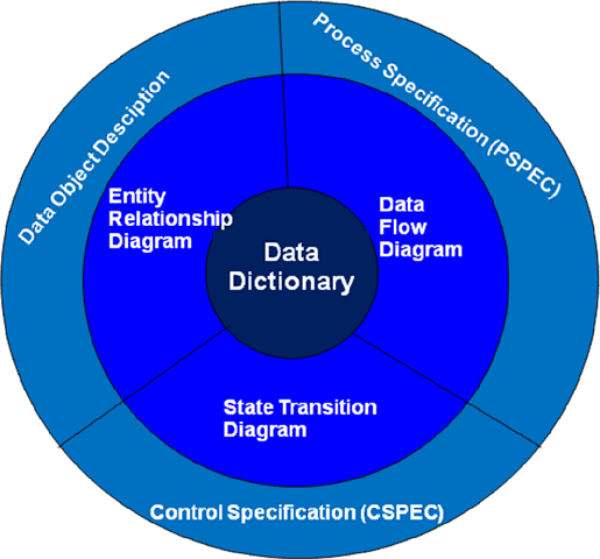

In [4]:
print("Bentuk (tinggi, lebar, kanal):", img.shape)
print("Tipe data:", img.dtype)
print("Nilai piksel kiri-atas (B, G, R):", img[0, 0])
cv2_imshow(img)


In [5]:
# Konversi gambar berwarna (3 kanal BGR) menjadi derajat keabuan / grayscale (1 kanal)


abu = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)         # hitam-putih (1 kanal)
mini = cv2.resize(abu, (8, 8), interpolation=cv2.INTER_AREA)
print(mini)                                         # 64 angka = "gambar" 8x8
print("Nilai Piksel Terenda(Gelap):", mini.min(), " Tertinggi(Ter:", mini.max())


[[255 229 139  94 108 142 229 255]
 [229 109  62  34  36  76 106 229]
 [146  84  35  28  29  42  75 148]
 [103  67  66  54  41  70  48  96]
 [ 95  38  29  44  41  29  44  95]
 [138  58  29  52  52  29  64 139]
 [227  96  56  58  36  60  97 228]
 [255 227 152 110 109 154 228 255]]
Nilai Piksel Terenda(Gelap): 28  Tertinggi(Ter: 255


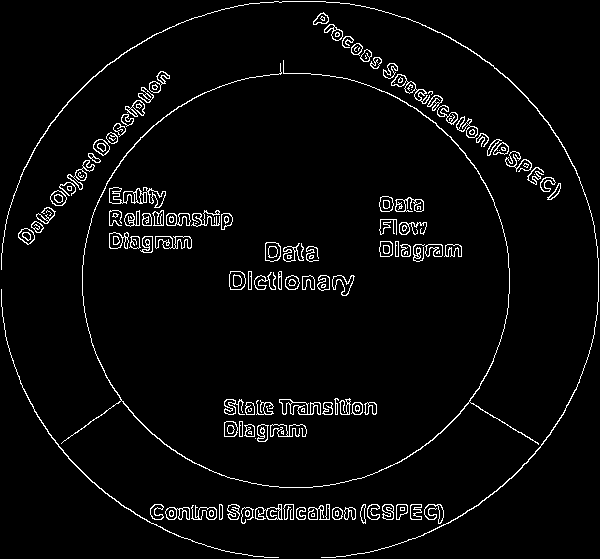

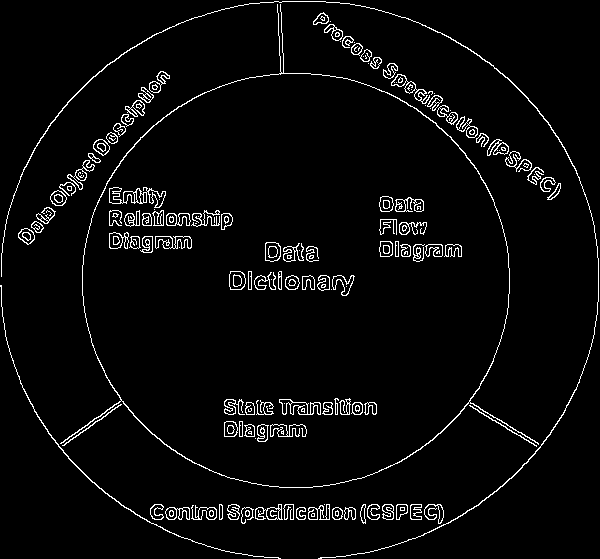

In [6]:
# Haluskan gambar terlebih dahulu untuk meredam bintik derau (noise)
blur = cv2.GaussianBlur(abu, (5, 5), 0)


# Bandingkan deteksi tepi dengan ambang batas ketat vs. ambang batas sensitif
tepi_a = cv2.Canny(blur, 100, 200)
tepi_b = cv2.Canny(blur, 30, 80)
cv2_imshow(tepi_a)
cv2_imshow(tepi_b)
